In [1]:
from typing import List
import numpy as np
import scipy.sparse as sp

from Components.Controllers import LTI_LQRc_RHG

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

In [3]:
A = np.array([[1, 1], [0, 1]])  # (2x2)

B0 = np.array([[1], [0]])
B1 = np.array([[0], [1]])
B2 = np.array([[1, 0], [1, 1]])
B_stack = [B0, B1, B2]
B_minus_v = [np.hstack([B1,B2]), np.hstack([B0,B2]), np.hstack([B0,B1])]

C = np.array([[1], [0]])

In [4]:
nx = 2
nu = 4
Nv = 3
nu_v = [1, 1, 2]
K=3

In [5]:
def form_B_tilde(A_powers: np.ndarray, B: np.ndarray) -> List[sp.lil_array]:
    B_tilde_v = []
    # Loop over agents
    for v, B_v in enumerate(B):
        # Compute all needed A^k B: shape (K, nx, nu)
        AkB = np.einsum('kij,jv->kiv', A_powers, B_v)
        # Lower triangular indices
        i_idx, j_idx = np.tril_indices(K)

        # Fetch the right A^k B for each block
        blocks = AkB[i_idx - j_idx]  # shape (num_blocks, nx, nu)

        # Step 4: Place blocks into final array
        result = sp.lil_array(((K+1) * nx, K * nu_v[v]))
        for idx, (i, j) in enumerate(zip(i_idx, j_idx)):
            result[(i+1)*nx:(i+2)*nx, j*nu_v[v]:(j+1)*nu_v[v]] = blocks[idx]
        B_tilde_v.append(result)
    
    return B_tilde_v

In [6]:
A_powers = np.array([np.linalg.matrix_power(A, k) for k in range(K + 1)])
A_powers

array([[[1, 0],
        [0, 1]],

       [[1, 1],
        [0, 1]],

       [[1, 2],
        [0, 1]],

       [[1, 3],
        [0, 1]]])

In [7]:
B_tilde = form_B_tilde(A_powers, B_stack)
[mat.toarray() for mat in B_tilde]

[array([[0., 0., 0.],
        [0., 0., 0.],
        [1., 0., 0.],
        [0., 0., 0.],
        [1., 1., 0.],
        [0., 0., 0.],
        [1., 1., 1.],
        [0., 0., 0.]]),
 array([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [1., 0., 0.],
        [1., 0., 0.],
        [1., 1., 0.],
        [2., 1., 0.],
        [1., 1., 1.]]),
 array([[0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [2., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [3., 2., 2., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])]

In [8]:
Q_v = [np.array([[1,0], [0,i]]) for i in range(3)]
R_v = [np.array([[i]]) for i in range(2)] + [np.array([[2, 0], [0, 1]])]
M_v = [np.array([[i], [1]]) for i in range(2)] + [np.array([[2, 0], [0, 1]])]
L_v = [np.array([[1]]) for _ in range(2)] + [np.array([[0, 1]])]

In [9]:
H_x = np.zeros((2,2))
h_x = np.ones((2,1))
H_u = np.zeros((4,4))
h_u = np.ones((4,1))

In [10]:
# ctrl = LTI_LQRc_RHG(K, nx, nu, Nv, nu_v,
#                  A, B_stack, B_minus_v, C,
#                  Q_v, R_v, M_v, L_v,
#                  H_x, h_x, H_u, h_u)
# x_0 = np.array([[0], [0]])
# ctrl.step(x_0)

# 17.04.2025: Debug non-convergence

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel
from Components.Controllers import LTI_LQRc_RHG

In [12]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [13]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file)
model = SquareCoarseModel(parameter_file)

### Check model oscillations

In [14]:
T_sim = 100

In [15]:
h_0 = model.translate_state(system.get_state()[0,:,:])
heads = np.zeros((model.n_col * model.n_row, T_sim))
q_2 = np.zeros((4, 1))
q_1 = q_2.copy()
q_1[0] = -500

In [16]:
B = np.hstack([B.toarray() for B in model.B_v])

In [17]:
heads[:,[0]] = h_0
for t in range(1,T_sim//4):
    heads[:,[t]] = model.A @ heads[:,[t-1]] + B @ q_1 + model.C
for t in range(T_sim//4, T_sim):
    heads[:,[t]] = model.A @ heads[:,[t-1]] + B @ q_2 + model.C

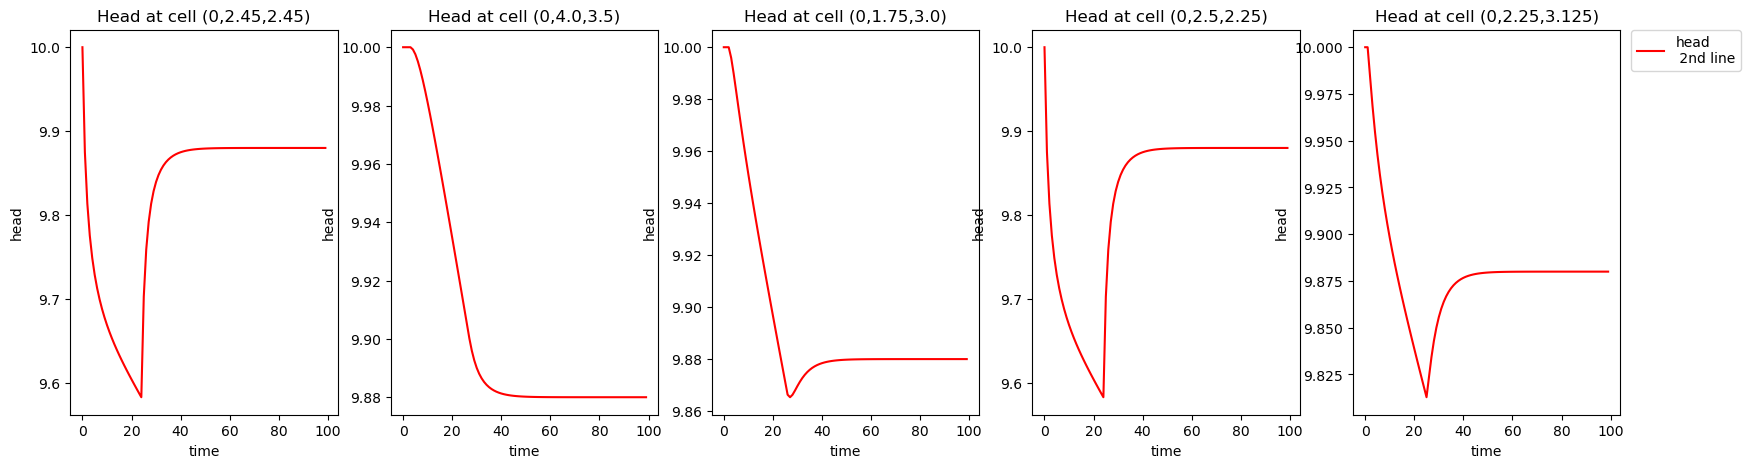

In [ ]:
Lx, Ly = 1000, 1000
obsWell = [[0, 490, 490], [0, 800, 700], [0, 350, 600], [0,500, 450], [0, 450, 625]]

fig = plt.figure(figsize=(20,5))
for ii in range(5):
    col_i = int(obsWell[ii][1] * model.n_col / Lx)
    row_i = int(obsWell[ii][2] * model.n_row / Ly)

    ax = fig.add_subplot(1, 5, ii+1)
    ttl = f"Head at cell ({0},{obsWell[ii][1]/200},{obsWell[ii][2]/200})"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    ax.set_ylabel("head")
    ax.plot(heads[col_i + model.n_col*row_i,:], "r-")
    #ax.set_ylim([8.7, 10])

No oscillations

### Check aggregated matrices

In [19]:
# Initialize Controller
controller = LTI_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], [B.toarray() for B in model.B_minus_v], model.C,
    model.H_x, model.h_x, model.H_u, model.h_u,
    Q_v = None, R_v = None, M_v = [G.toarray() for G in model.Gamma_v], L_v = [Xi for Xi in model.Xi_v]
)

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ got an unexpected keyword argument 's'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/mi

AttributeError: 'SquareCoarseModel' object has no attribute 'B_minus_v'

In [ ]:
assert (controller.A_tilde[:25, :] == np.eye(25)).all()
assert (controller.A_tilde[25:50, :] == model.A).all()
assert not (controller.A_tilde[50:75, :] - model.A @ model.A).round(5).any()
assert not (controller.A_tilde[75:100, :] - model.A @ model.A @ model.A).round(5).any()

In [ ]:
Knu = controller.B_tilde.shape[1]
assert (controller.B_tilde[:25, :] == np.zeros((25,Knu))).all()
assert (controller.B_tilde[25:50, :4] == B).all()
assert (controller.B_tilde[25:50, 4:] == np.zeros((25,Knu-4))).all()
assert (controller.B_tilde[50:75, :4] == model.A @ B).all()
assert (controller.B_tilde[50:75, 4:8] == B).all()
assert (controller.B_tilde[50:75, 8:] == np.zeros((25,Knu-8))).all()
assert not (controller.B_tilde[75:100, :4] - model.A @ model.A @ B).round(10).any()
assert (controller.B_tilde[75:100, 4:8] == model.A @ B).all()
assert (controller.B_tilde[75:100, 8:12] == B).all()

In [ ]:
U = np.vstack((np.kron(np.ones((5,1)), q_1), np.kron(np.ones((5,1)), q_2)))
X = controller.A_tilde @ h_0 + controller.B_tilde @ U + controller.C_tilde

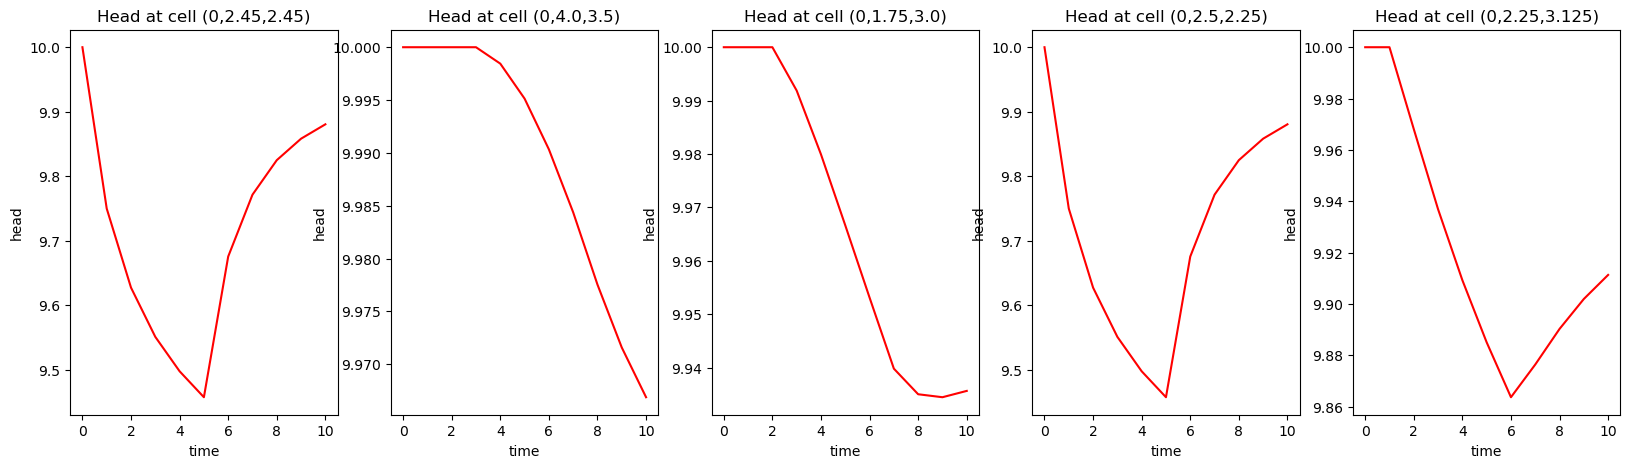

In [ ]:
heads = X.reshape(11,25).T
fig = plt.figure(figsize=(20,5))
for ii in range(5):
    col_i = int(obsWell[ii][1] * model.n_col / Lx)
    row_i = int(obsWell[ii][2] * model.n_row / Ly)

    ax = fig.add_subplot(1, 5, ii+1)
    ttl = f"Head at cell ({0},{obsWell[ii][1]/200},{obsWell[ii][2]/200})"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    ax.set_ylabel("head")
    ax.plot(heads[col_i + model.n_col*row_i,:], "r-")
    #ax.set_ylim([8.7, 10])

### Check constraints

In [ ]:
controller.H_u.toarray() , controller.h_u.toarray().T

(array([[ 1.,  0.,  0.,  0.],
        [ 0.,  1.,  0.,  0.],
        [ 0.,  0.,  1.,  0.],
        [ 0.,  0.,  0.,  1.],
        [-1.,  0.,  0.,  0.],
        [ 0., -1.,  0.,  0.],
        [ 0.,  0., -1.,  0.],
        [ 0.,  0.,  0., -1.]]),
 array([[   0.,    0.,    0.,    0., 2000., 1000., 1000., 1000.]]))

In [ ]:
(controller.H_u.toarray() @ np.array([[-1000,-1000,-3,-4]]).T <= controller.h_u.toarray()).T

array([[ True,  True,  True,  True,  True,  True,  True,  True]])

In [ ]:
controller.H_x.data, controller.h_x.toarray().T

(array([[-1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.,
         -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.]]),
 array([[40. , 40. , 40. , 40. , 40. , 40. , 40. , 40. , 35. , 40. , 40. ,
         40. , -8.5, 40. , 40. , 40. , 40. , 40. , 40. , 40. , 40. , 40. ,
         40. , 30. , 40. ]]))

In [ ]:
H, h = controller._compute_constraints(h_0)
H, h

(<COOrdinate sparse matrix of dtype 'float64'
 	with 3137 stored elements and shape (355, 40)>,
 <COOrdinate sparse array of dtype 'float64'
 	with 355 stored elements and shape (355, 1)>)

In [ ]:
(H @ np.kron(np.ones((10,1)), q_1) <= h).all()

np.True_

### Check cost

In [ ]:
model.Xi_v

[array([[19.]]), array([[35., 35.]]), array([[17.]])]

In [ ]:
[h_0.T @ model.Gamma_v[i] for i in range(3)]

[array([[-40.]]), array([[-40., -40.]]), array([[-20.]])]

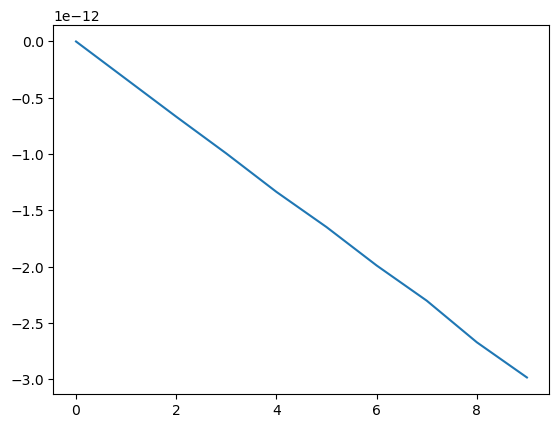

In [ ]:
u = np.linspace(0,10,10)
plt.plot((h_0.T @ model.Gamma_v[0] * u + model.Xi_v[0] * u).flatten())

Given an initial head, it is a linear function in u

Let't plot the gradient as a function of h_0

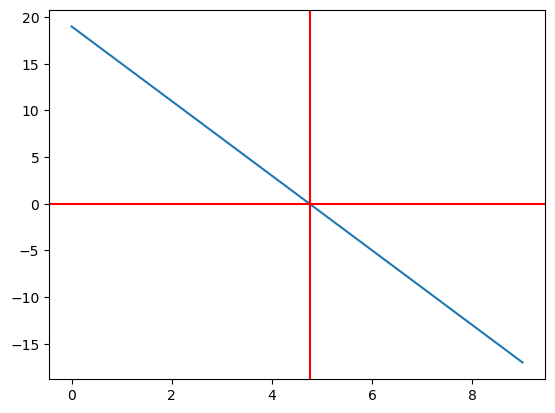

In [ ]:
plt.plot([(x*np.ones((25,1)).T @ model.Gamma_v[0] + model.Xi_v[0]).flatten() for x in range(10)])
plt.axhline(0, c='r')
plt.axvline(4.75, c='r')

In [ ]:
model.Gamma_v[0].toarray().T

array([[ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., -4.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]])

In [ ]:
print([(Q_v == 0).all() for Q_v in controller.tilde_Q_v])
print([not (R_v != 0).toarray().any() for R_v in controller.tilde_R_minus_v_minus_v])
print([not (M_v != 0).any() for M_v in controller.tilde_M_x_u_minus_v])

[np.True_, np.True_, np.True_]
[True, True, True]
[True, True, True]


In [ ]:
controller.B_v_tilde[0].shape

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ got an unexpected keyword argument 's'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ missing 1 required positional argument: 'value'. This will become an error in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/

AttributeError: 'LTI_LQRc_RHG' object has no attribute 'B_v_tilde'

In [ ]:
controller.tilde_R_v_v[0].toarray()

array([[ 0.        , -0.002     , -0.00098   , -0.00061025, -0.00042647,
        -0.00032167, -0.00025638, -0.00021289, -0.00018242, -0.00016024],
       [ 0.        ,  0.        , -0.002     , -0.00098   , -0.00061025,
        -0.00042647, -0.00032167, -0.00025638, -0.00021289, -0.00018242],
       [ 0.        ,  0.        ,  0.        , -0.002     , -0.00098   ,
        -0.00061025, -0.00042647, -0.00032167, -0.00025638, -0.00021289],
       [ 0.        ,  0.        ,  0.        ,  0.        , -0.002     ,
        -0.00098   , -0.00061025, -0.00042647, -0.00032167, -0.00025638],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        -0.002     , -0.00098   , -0.00061025, -0.00042647, -0.00032167],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        , -0.002     , -0.00098   , -0.00061025, -0.00042647],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        , -0.002     

In [ ]:
# Initialize receding horizon
receding_horizon = RecedingHorizon(system, model, controller)
# Run loop
receding_horizon.run(time_period=52)

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ got an unexpected keyword argument 's'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ missing 1 required positional argument: 'value'. This will become an error in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/

RuntimeError: MODFLOW did not terminate normally.

# 24.04.2025

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel
from Components.Controllers import LTI_LQRc_RHG

In [ ]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [ ]:
T_sim = 100

In [ ]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = SquareCoarseModel(parameter_file, boundary_condition="Constant Head")

In [ ]:
# Initialize Controller
controller = LTI_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    Q_v = None, R_v = None, M_v = [G.toarray() for G in model.Gamma_v], L_v = [Xi for Xi in model.Xi_v]
)

In [ ]:
h_0 = model.translate_state(system.get_state()[0,:,:])

In [ ]:
inputs = controller.step(h_0)
pumping_rates = model.translate_input(inputs[[0], :].T)

RuntimeError: [RHG] Error: solver fbrs was unable to converge (Maximum number of iterations exceeded)

In [ ]:
pumping_rates

array([[-1000.],
       [-1000.],
       [-1000.],
       [-1000.],
       [-1000.]])

In [ ]:
(model.A @ h_0 + (model.B_v[0] @ inputs[[0], 0])[:,np.newaxis] + model.B_v[1] @ inputs[[0], 1:3].T + (model.B_v[2] @ inputs[[0], 3])[:,np.newaxis] + model
.C).T

array([[10.  , 10.  , 10.  , 10.  , 10.  , 10.  , 10.  , 10.  ,  9.75,
        10.  , 10.  , 10.  ,  9.5 ,  9.75, 10.  , 10.  , 10.  , 10.  ,
        10.  , 10.  , 10.  , 10.  , 10.  ,  9.75, 10.  ]])

In [ ]:
h = (controller.A_tilde @ h_0 + (controller.B_v_tilde[0] @ inputs[:, 0])[:,np.newaxis] + controller.B_v_tilde[1] @ inputs[:, 1:3].reshape(20,1) + (controller.B_v_tilde[2] @ inputs[:, 3])[:,np.newaxis] + controller
.C_tilde).reshape((11,25))

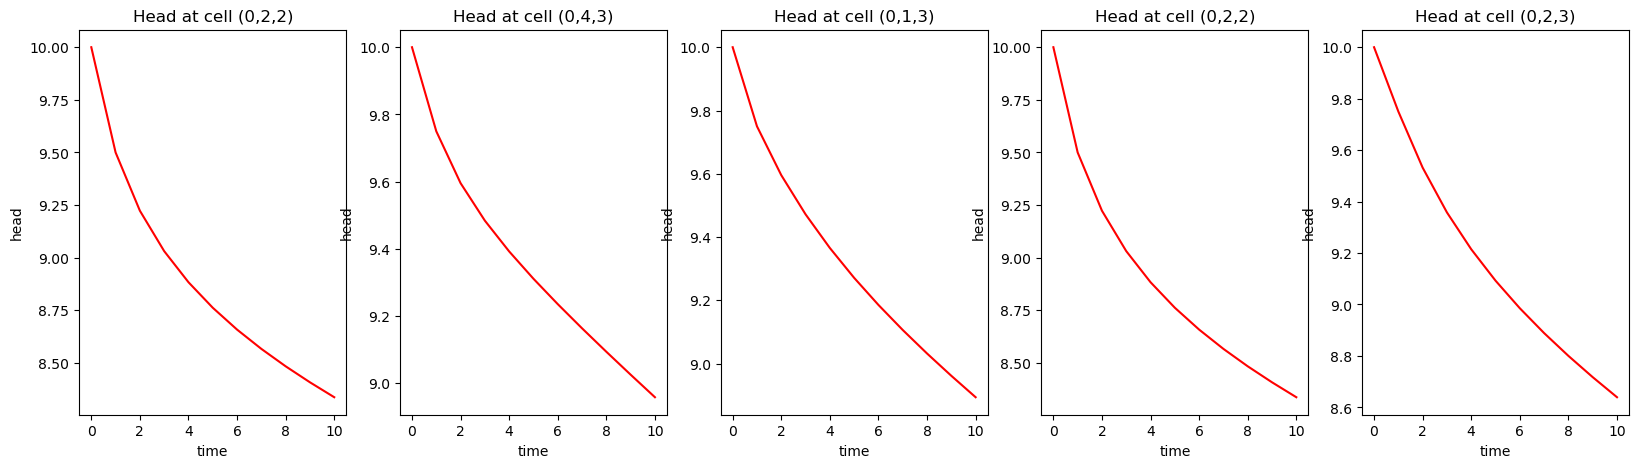

In [ ]:
Lx, Ly = 1000, 1000
obsWell = [[0, 490, 490], [0, 800, 700], [0, 350, 600], [0,500, 450], [0, 450, 625]]

fig = plt.figure(figsize=(20,5))
for ii in range(5):
    row_i = int(obsWell[ii][1] * model.n_col / Lx)
    col_i = int(obsWell[ii][2] * model.n_row / Ly)

    ax = fig.add_subplot(1, 5, ii+1)
    ttl = f"Head at cell ({0},{row_i},{col_i})"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    ax.set_ylabel("head")
    ax.plot(h[:,col_i + model.n_col*row_i], "r-")
    #ax.set_ylim([8.7, 10])

In [ ]:
U = inputs.T.flatten()[:,np.newaxis]
U[10:, :]=-1000

In [ ]:
U.T @ controller.F @ U + (controller.f_x @ h_0 + controller.f).T @ U

array([[-2770024.56940868]])

In [ ]:
U_opt = np.hstack([inputs[:,0], inputs[:,1:3].flatten(), inputs[:,3]])[:, np.newaxis]

In [ ]:
U_opt.T @ controller.F @ U_opt + (controller.f_x @ h_0 + controller.f).T @ U_opt

array([[-2770024.56940868]])

In [ ]:
(controller.f_x @ h_0 + controller.f).T @ U, (controller.f_x @ h_0 + controller.f).T @ U_opt

(array([[-3050000.00000008]]), array([[-3050000.00000008]]))

In [ ]:
U.T @ controller.F @ U, U_opt.T @ controller.F @ U_opt

(array([[279975.4305914]]), array([[279975.4305914]]))

In [ ]:
cost = np.zeros((10,))
for i in range(10):
    cost[i:] += 4 * inputs[i, 1] * (10-h[i,3 + model.n_col*2]) - 5 * inputs[i, 1]

In [ ]:
cost

array([ 5000.        ,  9000.        , 12127.5       , 14558.76875   ,
       16417.28282813, 17787.64981395, 18729.17602448, 19284.56501329,
       19485.39290448, 19355.59859269])

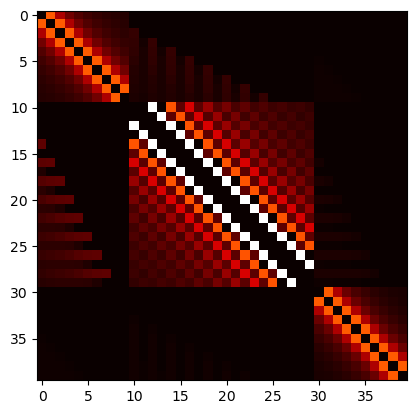

In [ ]:
plt.imshow(controller.F.toarray(), cmap='hot', interpolation='nearest')

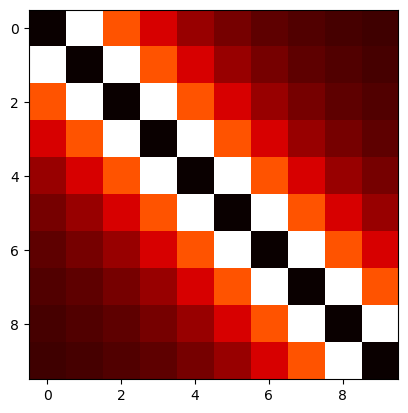

In [ ]:
v = 0
Q_v_diag = np.kron(np.eye(controller.K+1), controller.Q_v[v])
R_v_diag = np.kron(np.eye(controller.K), controller.R_v[v])
M_v_diag = np.kron(np.eye(controller.K), controller.M_v[v])
M_v_diag = np.vstack([M_v_diag, np.zeros((controller.nx, M_v_diag.shape[1]))])
R_vv = controller.B_v_tilde[v].T @ Q_v_diag @ controller.B_v_tilde[v] + controller.B_v_tilde[v].T @ M_v_diag + R_v_diag
plt.imshow((R_vv + R_vv.T), cmap='hot', interpolation='nearest')

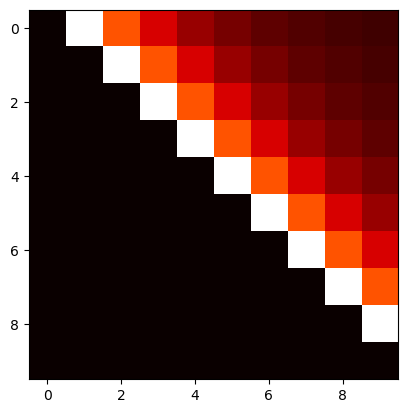

In [ ]:
plt.imshow(R_vv, cmap='hot', interpolation='nearest')

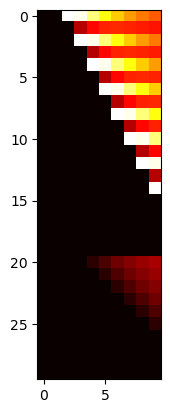

In [ ]:
B_minus_v_tilde = sp.hstack(controller.B_v_tilde[:v] + controller.B_v_tilde[v+1:])
plt.imshow((B_minus_v_tilde.T @ M_v_diag), cmap='hot', interpolation='nearest')

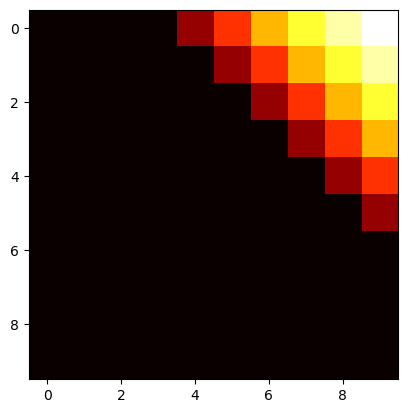

In [ ]:
plt.imshow((controller.B_v_tilde[2].T @ M_v_diag), cmap='hot', interpolation='nearest')

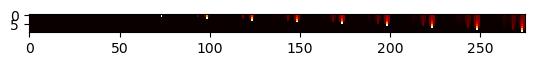

In [ ]:
plt.imshow(controller.B_v_tilde[2].T.toarray(), cmap='hot', interpolation='nearest')

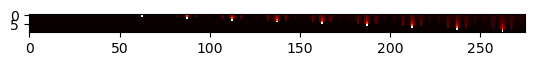

In [ ]:
plt.imshow(controller.B_v_tilde[0].T.toarray(), cmap='hot', interpolation='nearest')

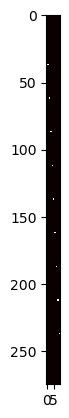

In [ ]:
plt.imshow(M_v_diag, cmap='hot', interpolation='nearest')

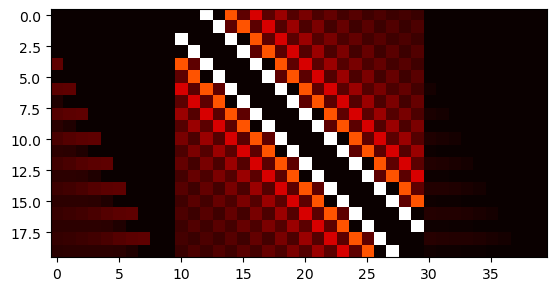

In [ ]:
plt.imshow(controller.F.toarray()[10:30,:], cmap='hot', interpolation='nearest')

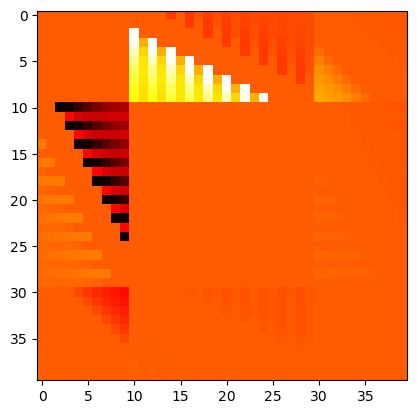

In [ ]:
plt.imshow((controller.F.toarray() - controller.F.toarray().T), cmap='hot', interpolation='nearest')

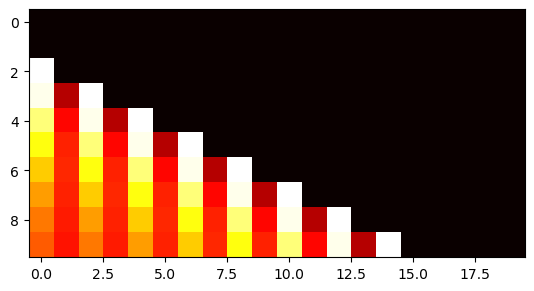

In [ ]:
M_v_diag_0 = np.kron(np.eye(controller.K), controller.M_v[v])
M_v_diag_0 = np.vstack([M_v_diag_0, np.zeros((controller.nx, M_v_diag_0.shape[1]))])
plt.imshow((controller.B_v_tilde[1].T @ M_v_diag_0).T, cmap='hot', interpolation='nearest')

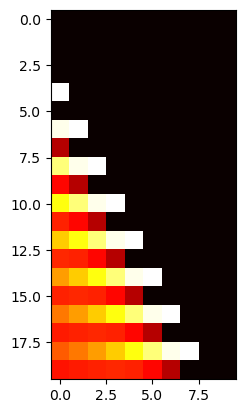

In [ ]:
M_v_diag_1 = np.kron(np.eye(controller.K), controller.M_v[1])
M_v_diag_1 = np.vstack([M_v_diag_1, np.zeros((controller.nx, M_v_diag_1.shape[1]))])
plt.imshow((controller.B_v_tilde[0].T @ M_v_diag_1).T, cmap='hot', interpolation='nearest')

In [ ]:
eigval, eigvec = np.linalg.eig(controller.F.toarray())
eigval[eigval>0], eigval[eigval<0]

(array([4.50374362e-03+0.00000000e+00j, 3.02710246e-03+0.00000000e+00j,
        1.81015531e-03+1.34725979e-05j, 1.81015531e-03-1.34725979e-05j,
        1.71479464e-03+1.24450355e-04j, 1.71479464e-03-1.24450355e-04j,
        9.09365408e-04+2.31758134e-05j, 9.09365408e-04-2.31758134e-05j,
        8.70824548e-04+0.00000000e+00j, 4.64991743e-04+0.00000000e+00j,
        3.55547526e-04+0.00000000e+00j, 2.67551983e-04+1.88452190e-05j,
        2.67551983e-04-1.88452190e-05j, 4.50092044e-06+0.00000000e+00j,
        1.08595885e-06+0.00000000e+00j]),
 array([-0.00147852+0.j, -0.00138627+0.j, -0.00125023+0.j, -0.00122912+0.j,
        -0.0012125 +0.j, -0.00114467+0.j, -0.00103772+0.j, -0.00100119+0.j,
        -0.00087687+0.j, -0.00020371+0.j, -0.00023568+0.j, -0.00026205+0.j,
        -0.0003158 +0.j, -0.00039104+0.j, -0.00040035+0.j, -0.00051698+0.j,
        -0.00051542+0.j, -0.00059821+0.j, -0.00059547+0.j, -0.00069334+0.j,
        -0.00067961+0.j, -0.00067698+0.j, -0.00063147+0.j, -0.00065078+0.j

In [ ]:
np.real(eigval).max(), np.real(eigval).min()

(np.float64(0.004503743623900146), np.float64(-0.0014785208008293038))

In [ ]:
eigval, eigvec = np.linalg.eig(0.5*(controller.F.T + controller.F).toarray())
eigval.min()

np.float64(-0.0014789752693548448)

In [ ]:
(controller.f_x @ h_0 + controller.f).T

array([[21., 21., 21., 21., 21., 21., 21., 21., 21., 21.,  5.,  5.,  5.,
         5.,  5.,  5.,  5.,  5.,  5.,  5.,  5.,  5.,  5.,  5.,  5.,  5.,
         5.,  5.,  5.,  5.,  3.,  3.,  3.,  3.,  3.,  3.,  3.,  3.,  3.,
         3.]])

In [ ]:
(controller.f_x @ h_0).T

array([[40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40.,
        40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40.,
        40., 40., 40., 40., 20., 20., 20., 20., 20., 20., 20., 20., 20.,
        20.]])

In [ ]:
controller.f.T.toarray()

array([[-19., -19., -19., -19., -19., -19., -19., -19., -19., -19., -35.,
        -35., -35., -35., -35., -35., -35., -35., -35., -35., -35., -35.,
        -35., -35., -35., -35., -35., -35., -35., -35., -17., -17., -17.,
        -17., -17., -17., -17., -17., -17., -17.]])

In [ ]:
controller.C_tilde[controller.C_tilde != 0]

array([2.55      , 1.275     , 1.275     , 1.275     , 2.55      ,
       1.275     , 1.275     , 1.275     , 1.275     , 1.275     ,
       1.275     , 2.55      , 1.275     , 1.275     , 1.275     ,
       2.55      , 4.124625  , 2.3874375 , 2.224875  , 2.3874375 ,
       4.124625  , 2.3874375 , 0.325125  , 0.1625625 , 0.325125  ,
       2.3874375 , 2.224875  , 0.1625625 , 0.1625625 , 2.224875  ,
       2.3874375 , 0.325125  , 0.1625625 , 0.325125  , 2.3874375 ,
       4.124625  , 2.3874375 , 2.224875  , 2.3874375 , 4.124625  ,
       5.17986281, 3.29585906, 2.99471203, 3.29585906, 5.17986281,
       3.29585906, 0.80956125, 0.44623406, 0.80956125, 3.29585906,
       2.99471203, 0.44623406, 0.08290688, 0.44623406, 2.99471203,
       3.29585906, 0.80956125, 0.44623406, 0.80956125, 3.29585906,
       5.17986281, 3.29585906, 2.99471203, 3.29585906, 5.17986281,
       5.92857684, 4.03544829, 3.6397478 , 4.03544829, 5.92857684,
       4.03544829, 1.35091876, 0.81748922, 1.35091876, 4.03544

# 28.04

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel
from Components.Controllers import LTI_LQRc_RHG

In [ ]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [ ]:
T_sim = 100

In [ ]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = SquareCoarseModel(parameter_file, boundary_condition="Constant Head")

In [ ]:
# Initialize Controller
controller = LTI_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    Q_v = None, R_v = None, M_v = [G.toarray() for G in model.Gamma_v], L_v = [Xi for Xi in model.Xi_v]
)

In [ ]:
h_0 = model.translate_state(system.get_state()[0,:,:])

In [ ]:
m = gp.Model("matrix1")

u = m.addMVar(shape=controller.K*controller.nu, lb=-np.inf, vtype=gp.GRB.CONTINUOUS, name="U")

m.addConstr((controller.H.toarray() @ u)[:,np.newaxis] <= (controller.h_x_0 @ h_0 + controller.h), name="H")

m.setObjective(u.T @ controller.F @ u + (controller.f_x @ h_0 + controller.f).T @ u, gp.GRB.MINIMIZE)

Set parameter Username
Academic license - for non-commercial use only - expires 2026-04-28


In [ ]:
m.optimize()

Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (mac64[x86] - Darwin 24.4.0 24E263)

CPU model: Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 355 rows, 40 columns and 3137 nonzeros
Model fingerprint: 0x4e801684
Model has 520 quadratic objective terms
Coefficient statistics:
  Matrix range     [5e-09, 1e+00]
  Objective range  [3e+00, 2e+03]
  QObjective range [2e-06, 4e-01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+01, 2e+03]
Presolve removed 355 rows and 0 columns

Continuous model is non-convex -- solving as a MIP

Found heuristic solution: objective 0.0000000
Presolve removed 355 rows and 40 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.02 seconds (0.00 work units)
Thread count was 1 (of 8 available processors)

Solution count 2: -2.54573e+07 0 
No other solutions better than -2.54573e+07

Optimal solution

In [ ]:
u_opt = -1000 * np.ones((controller.K * controller.nu))
u_opt.T @ controller.F @ u_opt + (controller.f_x @ h_0 + controller.f).T @ u_opt

array([-186189.59885996])

In [ ]:
m.ObjVal

-312816.8082959534

In [ ]:
u.X

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ got an unexpected keyword argument 's'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ missing 1 required positional argument: 'value'. This will become an error in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/

GurobiError: Index 0 out of range for attribute 'X'

In [ ]:
h = (controller.A_tilde @ h_0 + (controller.B_v_tilde[0] @ u.X[:10])[:,np.newaxis] + controller.B_v_tilde[1] @ u.X[10:30].reshape(20,1) + (controller.B_v_tilde[2] @ u.X[30:])[:,np.newaxis] + controller
.C_tilde).reshape((11,25))

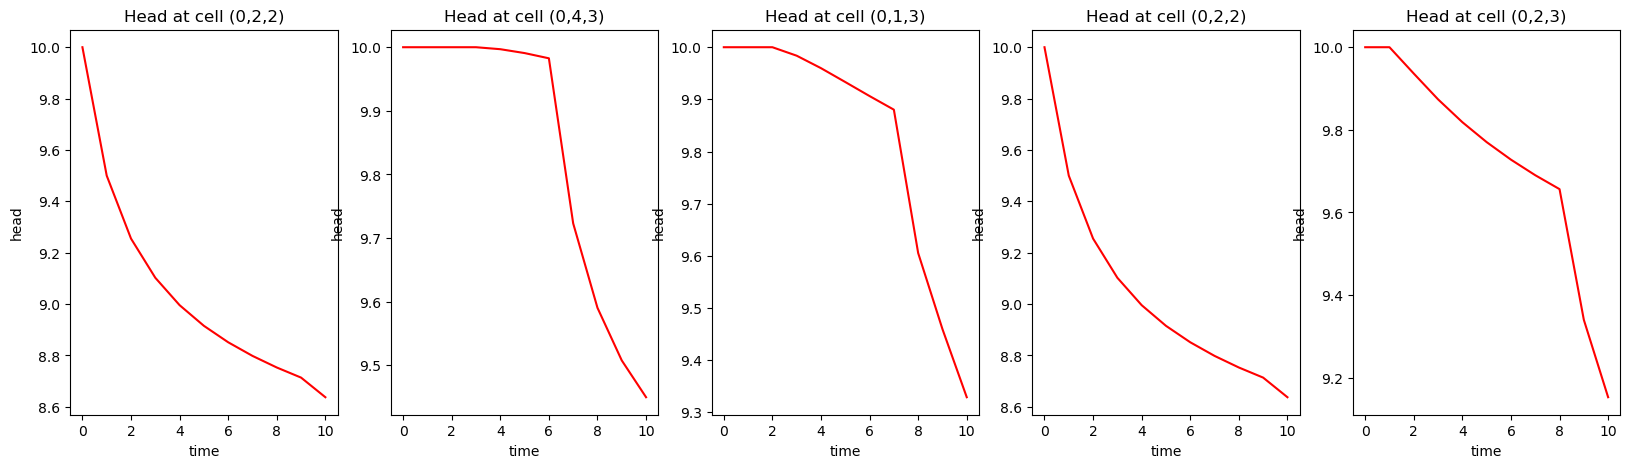

In [ ]:
Lx, Ly = 1000, 1000
obsWell = [[0, 490, 490], [0, 800, 700], [0, 350, 600], [0,500, 450], [0, 450, 625]]

fig = plt.figure(figsize=(20,5))
for ii in range(5):
    row_i = int(obsWell[ii][1] * model.n_col / Lx)
    col_i = int(obsWell[ii][2] * model.n_row / Ly)

    ax = fig.add_subplot(1, 5, ii+1)
    ttl = f"Head at cell ({0},{row_i},{col_i})"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    ax.set_ylabel("head")
    ax.plot(h[:,col_i + model.n_col*row_i], "r-")
    #ax.set_ylim([8.7, 10])

In [134]:
u_opt = -1000 * np.ones((controller.K * controller.nu))
u_opt[:10] = 0
u_opt.T @ controller.F @ u_opt + (controller.f_x @ h_0 + controller.f).T @ u_opt

array([-23272.34616738])

In [133]:
m.ObjVal

-25457256.369323913

In [11]:
ones = np.ones((controller.K * controller.nu))
2000 * 2000 * ones[:10].T @ controller.F[:10,:10] @ ones[:10], -2000 * (controller.f_x @ h_0 + controller.f).T[:,:10] @ ones[:10] 

(np.float64(72916.8277805104), array([-20000.]))

In [12]:
1000 * 1000 * ones[10:].T @ controller.F[10:,10:] @ ones[10:], -1000 * (controller.f_x @ h_0 + controller.f).T[:,10:] @ ones[10:]

(np.float64(106727.65383262948), array([-130000.00000001]))

In [24]:
0.5 * 2000 * 2000 * ones[:10].T @ controller.F[:10,:10] @ ones[:10] -2000 * (controller.f_x @ h_0 + controller.f).T[:,:10] @ ones[:10], \
0.5 * 1000 * 1000 * ones[10:].T @ controller.F[10:,10:] @ ones[10:] -1000 * (controller.f_x @ h_0 + controller.f).T[:,10:] @ ones[10:]

(array([16458.41389025]), array([-76636.17308369]))

In [14]:
h_1 = (controller.A_tilde @ h_0 - 2000 * (controller.B_v_tilde[0] @ ones[:10])[:,np.newaxis] + controller.C_tilde).reshape((11,25))
h_2 = (controller.A_tilde @ h_0 - 1000 * controller.B_v_tilde[1] @ ones[10:30].reshape(20,1) - 1000 * (controller.B_v_tilde[2] @ ones[30:])[:,np.newaxis] + controller.C_tilde).reshape((11,25))

In [15]:
-2000 * (1*ones)[np.newaxis,:10] @ ones[:10], -1000 * (1*ones)[np.newaxis,10:] @ ones[10:]

(array([-20000.]), array([-30000.]))

In [16]:
-2 * (-2000) * (10. - h_1[:-1,2 + model.n_col*2].T) @ ones[:10], -(-1000) * (10. - np.hstack([h_2[:-1,j + model.n_col*i].T for i,j in [(4,3), (1,3), (2,3)]])) @ ones[10:]

(np.float64(36458.413890252355), np.float64(15776.691933064487))

In [17]:
-2000 * (1*ones)[np.newaxis,:10] @ ones[:10] - 2 * (-2000) * 10. * 10,  -2000 * (controller.f_x @ h_0 + controller.f).T[:,:10] @ ones[:10], -19* (-2000)* 10

(array([380000.]), array([-20000.]), 380000)

In [25]:
-2 * (-2000) * (10. - h_1[:-1,2 + model.n_col*2].T) @ ones[:10] -2000 * (1*ones)[np.newaxis,:10] @ ones[:10]

array([16458.41389025])

In [39]:
model.Xi_v, (controller.f_x @ h_0 + controller.f).T[:,:10], controller.f.toarray().T[:,:10]

([array([[-19.]]), array([[-35., -35.]]), array([[-17.]])],
 array([[21., 21., 21., 21., 21., 21., 21., 21., 21., 21.]]),
 array([[-19.        , -19.        , -19.        , -18.6683725 ,
         -17.92718504, -16.80664266, -15.38888654, -13.76674431,
         -12.0232779 , -10.22492273]]))

In [17]:
u_1 = np.kron([2,0,0,0], -1000*np.ones(10))
u_1.T @ controller.F @ u_1 + (controller.f_x @ h_0 + controller.f).T @ u_1

array([-274166.34443898])

In [175]:
(controller.f_x @ h_0 + controller.f).T

array([[-5999., -5999., -5999., -5999., -5999., -5999., -5999., -5999.,
        -5999., -5999.,   -75.,   -75.,   -75.,   -75.,   -75.,   -75.,
          -75.,   -75.,   -75.,   -75.,   -75.,   -75.,   -75.,   -75.,
          -75.,   -75.,   -75.,   -75.,   -75.,   -75.,   -37.,   -37.,
          -37.,   -37.,   -37.,   -37.,   -37.,   -37.,   -37.,   -37.]])

In [9]:
(controller.f_x @ h_0).T, controller.f.toarray().T

(array([[20.        , 20.        , 20.        , 19.83418625, 19.46359252,
         18.90332133, 18.19444327, 17.38337216, 16.51163895, 15.61246136,
         40.        , 40.        , 40.        , 40.        , 39.34975   ,
         38.6995    , 38.21506375, 36.761755  , 36.73004312, 34.59632496,
         35.02672871, 32.40220297, 33.2082155 , 30.27143062, 31.34818272,
         28.24382872, 29.49709129, 26.33398158, 27.68841083, 24.54444385,
         20.        , 17.45      , 15.225125  , 13.40828188, 11.92910341,
         10.71085361,  9.69163287,  8.82493904,  8.07653842,  7.42130813]]),
 array([[-19.        , -19.        , -19.        , -18.83418625,
         -18.46359252, -17.90332133, -17.19444327, -16.38337216,
         -15.51163895, -14.61246136, -35.        , -35.        ,
         -35.        , -35.        , -34.34975   , -33.6995    ,
         -33.21506375, -31.761755  , -31.73004312, -29.59632496,
         -30.02672871, -27.40220297, -28.2082155 , -25.27143062,
         -26.34

# 29.04

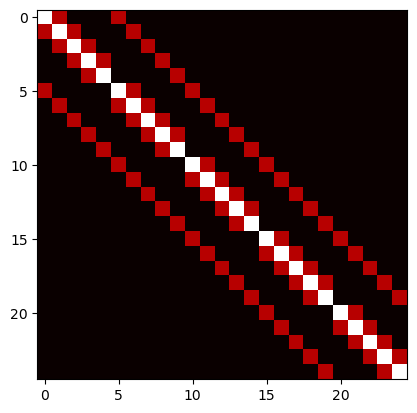

In [35]:
plt.imshow(controller.A, cmap='hot', interpolation='nearest')

In [46]:
np.linalg.eigvals(controller.A)

array([0.93167296, 0.04832704, 0.745     , 0.235     , 0.83833648,
       0.83833648, 0.14166352, 0.14166352, 0.71083648, 0.71083648,
       0.6175    , 0.6175    , 0.58333648, 0.58333648, 0.26916352,
       0.26916352, 0.3625    , 0.3625    , 0.39666352, 0.39666352,
       0.49      , 0.49      , 0.49      , 0.49      , 0.49      ])

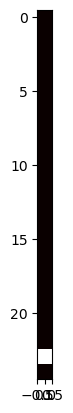

In [39]:
plt.imshow(controller.B_v[2], cmap='hot', interpolation='nearest')

In [43]:
controller.B_v[1]

array([[0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.00025],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.00025, 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ],
       [0.     , 0.     ]])